# Chapter 10 — Prompt Engineering 심화 + XAI (실습)

> **Chapter 10 · Part II**

**완성본** — Mock 모드와 실제 API 모드 모두 동작.

> mock 경로는 **프롬프트를 보지 않는** 결정론 정규식 분류기다. 네 변형이 같은 결과를 내므로
> 변형 간 비교(A/B) 는 API 키가 있을 때만 의미가 있다. mock 은 "규칙 기반 탐지기의 한계" 를
> 보여 주는 대조군으로만 쓴다.

## 실습 목표
1. 4 변형 (baseline / CoT / few-shot / full) — 본문 §10.2 SECURITY_SYSTEM 스키마 사용
2. 라벨된 로그 30 건 × 4 변형 분류 — 정확도·오답표·파싱 실패·출력 토큰(CoT 비용) 비교
3. 본문 §10.4.1 의 네 조건(근거·검증·반증·대응) 으로 설명 품질 채점
4. 정확도·XAI·비용을 함께 보고 최고 변형 선정 (동점 처리 포함)

In [1]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

In [2]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q anthropic
# !pip install -q pandas
# !pip install -q numpy
# !pip install -q matplotlib

In [3]:
import os, json, re
import numpy as np
import pandas as pd
from concurrent.futures import ThreadPoolExecutor

API_KEY = os.environ.get('ANTHROPIC_API_KEY')
USE_REAL = bool(API_KEY)
MODEL = 'claude-haiku-4-5'
PRICE_IN, PRICE_OUT = 1.0, 5.0     # Haiku 4.5 — 입력 $1 / 출력 $5 per MTok (본문 §9.3.1)
if USE_REAL:
    import anthropic
    client = anthropic.Anthropic(api_key=API_KEY)
    print(f'Real API mode — {MODEL}')
else:
    client = None
    print('Mock mode — 프롬프트 변형을 구분하지 못하는 정규식 분류기로 진행한다')

Real API mode — claude-haiku-4-5


---
## Step 0. 평가용 라벨 로그 30 건

A/B 의 결과가 프롬프트 차이를 재는지, 라벨 품질을 재는지는 데이터가 결정한다. 그래서 이 30 건은

- **서로 다른 30 개 로그**다 (같은 로그를 복제해 개수를 채우지 않는다).
- 각 라벨의 **판정 근거가 로그 안에 있다**. `Brute` 는 `/login` 401 한 줄이 아니라
  `fail_count_5m`(5 분 내 인증 실패 횟수) 이 근거이고, `PortScan` 은 `distinct_ports_1m` 이 근거다.
- **경계 사례**를 섞었다 — 난독화한 SQLi(`/**/`, 16 진수, 시간 지연), 인코딩한 XSS·경로 조작,
  공격처럼 보이는 정상(`select` 가 들어간 검색어, 보안 블로그 글 경로, 높은 빈도의 헬스 체크),
  낮은 빈도로 천천히 도는 포트 스캔, 실패가 반복되다 성공한 크리덴셜 스터핑.

경계 사례가 없으면 어떤 프롬프트를 써도 전부 맞히기 때문에 변형 간 차이가 드러나지 않는다.

In [4]:
def L(src, url, ua, status, label, method='GET', fail=0, ports=0, req=1):
    return ({'src': src, 'method': method, 'url': url, 'ua': ua, 'status': status,
             'fail_count_5m': fail, 'distinct_ports_1m': ports, 'req_count_1m': req}, label)

labeled = [
    # --- 정상 8 (뒤 3 건은 공격처럼 보이는 정상) ---
    L('10.0.0.11', '/index.html', 'Mozilla/5.0', 200, 'BENIGN'),
    L('10.0.0.12', '/products?category=laptop', 'Mozilla/5.0', 200, 'BENIGN'),
    L('10.0.0.13', '/static/app.js', 'Mozilla/5.0', 200, 'BENIGN'),
    L('10.0.0.14', '/login', 'Mozilla/5.0', 401, 'BENIGN', method='POST', fail=2),
    L('10.0.0.15', '/api/v1/users?limit=50', 'python-requests/2.31', 200, 'BENIGN', req=12),
    L('10.0.0.16', '/search?q=select a plan', 'Mozilla/5.0', 200, 'BENIGN'),
    L('10.0.0.17', '/blog/how-to-prevent-sql-injection', 'Mozilla/5.0', 200, 'BENIGN'),
    L('10.0.0.18', '/health', 'curl/8.4.0', 200, 'BENIGN', req=60),
    # --- SQLi 6 (뒤 3 건은 난독화) ---
    L('203.0.113.5', "/item?id=1' OR '1'='1", 'sqlmap/1.5', 401, 'SQLi'),
    L('203.0.113.5', '/item?id=1 UNION SELECT username,password FROM users--', 'curl/7.0', 500, 'SQLi'),
    L('203.0.113.6', '/login?user=admin%27--', 'Mozilla/5.0', 403, 'SQLi', method='POST'),
    L('203.0.113.7', '/item?id=1/**/AND/**/SLEEP(5)', 'Mozilla/5.0', 200, 'SQLi'),
    L('203.0.113.7', '/item?id=0x31%20or%201=1', 'Mozilla/5.0', 500, 'SQLi'),
    L('203.0.113.8', '/report?year=2026;SELECT pg_sleep(5)--', 'python-requests/2.31', 500, 'SQLi'),
    # --- XSS 5 (뒤 2 건은 인코딩·변종 태그) ---
    L('198.51.100.3', '/search?q=<script>alert(1)</script>', 'Mozilla/5.0', 200, 'XSS'),
    L('198.51.100.3', '/comment?text=<img src=x onerror=alert(1)>', 'Mozilla/5.0', 200, 'XSS', method='POST'),
    L('198.51.100.4', '/redirect?u=javascript:alert(document.cookie)', 'Mozilla/5.0', 302, 'XSS'),
    L('198.51.100.5', '/profile?name=%3Cscript%3Elocation%3D%27http%3A%2F%2Fevil%27%3C%2Fscript%3E',
      'Mozilla/5.0', 200, 'XSS'),
    L('198.51.100.6', '/search?q=<svg/onload=confirm(1)>', 'Mozilla/5.0', 200, 'XSS'),
    # --- Brute 5 (뒤 2 건은 401 이 아닌 경계) ---
    L('192.168.1.101', '/login', 'Mozilla/5.0', 401, 'Brute', method='POST', fail=48),
    L('192.168.1.102', '/api/token', 'python-requests/2.31', 401, 'Brute', method='POST', fail=120),
    L('192.168.1.103', '/admin/login', 'Mozilla/5.0', 401, 'Brute', method='POST', fail=25),
    L('192.168.1.104', '/login', 'curl/7.0', 403, 'Brute', method='POST', fail=61),
    L('192.168.1.105', '/login', 'Mozilla/5.0', 200, 'Brute', method='POST', fail=37),
    # --- PortScan 3 (마지막은 느린 스캔) ---
    L('45.76.0.9', '-', '-', 0, 'PortScan', method='CONNECT', ports=412, req=500),
    L('45.76.0.9', '-', '-', 0, 'PortScan', method='CONNECT', ports=1024, req=1100),
    L('45.76.0.10', '-', '-', 0, 'PortScan', method='CONNECT', ports=25, req=25),
    # --- Other 3 (경로 조작·명령 주입) ---
    L('203.0.113.9', '/download?file=../../../etc/passwd', 'curl/7.0', 200, 'Other'),
    L('203.0.113.9', '/view?f=%2e%2e%2f%2e%2e%2fwindows%2fwin.ini', 'Mozilla/5.0', 404, 'Other'),
    L('203.0.113.9', '/ping?host=8.8.8.8;cat /etc/passwd', 'curl/7.0', 200, 'Other'),
]
print(f'총 {len(labeled)} 건 · 중복 로그 {len(labeled) - len({json.dumps(l, sort_keys=True) for l, _ in labeled})} 건')
print(pd.Series([t for _, t in labeled]).value_counts().to_string())

총 30 건 · 중복 로그 0 건
BENIGN      8
SQLi        6
XSS         5
Brute       5
PortScan    3
Other       3


---
## Step 1. 4 가지 프롬프트 변형

네 변형은 **본문 §10.2 의 SECURITY_SYSTEM 스키마를 공유**한다(`fields_observed`·
`attack_techniques`·`category`·`severity`·`reasoning`·`recommended_actions`). 달라지는 것은
CoT 지시와 few-shot 예시뿐이므로, 결과 차이는 그 두 요소에서만 온다.

few-shot 예시는 **틀리기 쉬운 유형**으로 고른다 — 난독화한 SQLi, 공격처럼 보이는 정상,
맥락 필드로만 판정되는 Brute. 쉬운 예시는 어차피 맞히는 것을 한 번 더 알려 줄 뿐이다.
예시 로그는 평가 30 건에 들어 있지 않은 것으로 만들어 정답이 새지 않게 한다.

In [5]:
# === SOLUTION START ===
SECURITY_SYSTEM = '''당신은 SOC senior analyst 다 (Role).

로그 필드의 의미:
- url, ua, status: 요청 경로, User-Agent, 응답 코드
- fail_count_5m: 같은 출발지의 최근 5 분 인증 실패 횟수
- distinct_ports_1m: 최근 1 분간 접속 시도한 서로 다른 포트 수
- req_count_1m: 최근 1 분간 요청 수

JSON schema 로만 응답한다:
{
  "fields_observed": [{"name": "...", "value": "...", "normal": true}],
  "attack_techniques": ["T1190", ...],
  "category": "BENIGN|SQLi|XSS|DDoS|PortScan|Brute|Other",
  "severity": 1,
  "reasoning": "왜 그 판정인지",
  "recommended_actions": ["대응 1~3"]
}

규칙:
- fields_observed 의 value 는 로그에 있는 값을 그대로 옮긴다. 없는 정보는 만들지 않는다.
- reasoning 에는 판정 근거가 된 필드 값을 그대로 인용하고, 어떤 조건이면 판정이 뒤집히는지도 적는다.
- recommended_actions 는 BENIGN 이어도 최소 1 개 적는다 (예: 모니터링 유지).
- 확신 없으면 BENIGN, severity=1.'''

COT_SUFFIX = '''

반드시 다음 순서로 추론한 뒤 JSON 을 출력한다.
1. 핵심 필드 식별
2. 정상 베이스라인과 비교
3. 난독화·인코딩 해제 후 패턴 매칭
4. ATT&CK 매핑과 위험도 산정
5. 최종 JSON'''

EXAMPLES = '''

예시 1 — 난독화한 SQLi (주석으로 공백을 대체)
입력: {"url": "/news?id=9/**/UNION/**/SELECT/**/1", "ua": "Mozilla/5.0", "status": 500}
출력: {"fields_observed": [{"name": "url", "value": "/news?id=9/**/UNION/**/SELECT/**/1", "normal": false}],
 "attack_techniques": ["T1190"], "category": "SQLi", "severity": 4,
 "reasoning": "url 의 /**/ 는 공백을 대체하는 주석 난독화이며 해제하면 UNION SELECT 다. status 500 은 구문이 DB 까지 전달됐음을 뜻한다. 애플리케이션이 해당 파라미터를 문자열로만 쓴다면 판정이 뒤집힌다.",
 "recommended_actions": ["출발지 IP 차단", "해당 파라미터 바인딩 확인"]}

예시 2 — 공격처럼 보이는 정상 (키워드만 일치)
입력: {"url": "/faq?q=how to select a table", "ua": "Mozilla/5.0", "status": 200}
출력: {"fields_observed": [{"name": "url", "value": "/faq?q=how to select a table", "normal": true}],
 "attack_techniques": [], "category": "BENIGN", "severity": 1,
 "reasoning": "select 가 있지만 SQL 구문이 아니라 검색어의 일부이고 status 200 이다. 같은 출발지에서 UNION·주석 기호가 이어진다면 재판정이 필요하다.",
 "recommended_actions": ["모니터링 유지"]}

예시 3 — 맥락 필드로만 판정되는 Brute
입력: {"url": "/signin", "ua": "Mozilla/5.0", "status": 401, "fail_count_5m": 44}
출력: {"fields_observed": [{"name": "fail_count_5m", "value": "44", "normal": false}],
 "attack_techniques": ["T1110"], "category": "Brute", "severity": 3,
 "reasoning": "fail_count_5m 44 는 5 분 내 44 회 인증 실패로, 사람의 오타 범위를 벗어난다. url 한 줄만으로는 정상 실패와 구분되지 않는다. 같은 값이 배포 직후 자동화 클라이언트 오설정 때문이라면 판정이 달라진다.",
 "recommended_actions": ["계정 잠금 정책 확인", "출발지 IP 일시 차단"]}'''

PROMPTS = {
    'baseline': SECURITY_SYSTEM,
    'CoT': SECURITY_SYSTEM + COT_SUFFIX,
    'few-shot': SECURITY_SYSTEM + EXAMPLES,
    'full': SECURITY_SYSTEM + COT_SUFFIX + EXAMPLES,
}
for k, v in PROMPTS.items():
    print(f'{k:10s} {len(v):5d} chars')
# === SOLUTION END ===

baseline     702 chars
CoT          815 chars
few-shot    2069 chars
full        2182 chars


---
## Step 2. 분류 함수 (mock + real)

파싱에 실패한 응답을 `BENIGN` 으로 돌려주면 **정상 로그에서는 실패가 정답으로 채점된다.**
그래서 실패는 `category=None`, `parse_error=True` 로 따로 표시하고 별도로 센다.

In [6]:
# === SOLUTION START ===
ATTACK_TECH = {'SQLi': ['T1190'], 'XSS': ['T1059.007'], 'Brute': ['T1110'],
               'PortScan': ['T1046'], 'Other': ['T1083'], 'BENIGN': []}

def mock_classify(log, system=None):
    """프롬프트를 보지 않는 정규식 분류기. 변형 비교용이 아니라 규칙 기반 대조군이다."""
    url = log.get('url', '')
    low = url.lower()
    if re.search(r"union\s+select|or\s+'?1'?\s*=\s*'?1|sleep\(|or\s+1=1", url, re.I):
        cat = 'SQLi'
    elif re.search(r'<script|onerror=|javascript:|%3cscript|onload=', low):
        cat = 'XSS'
    elif '../' in low or '%2e%2e%2f' in low or ';cat ' in low:
        cat = 'Other'
    elif log.get('distinct_ports_1m', 0) >= 100:
        cat = 'PortScan'
    elif log.get('status') == 401 and log.get('fail_count_5m', 0) >= 10:
        cat = 'Brute'
    else:
        cat = 'BENIGN'
    return {'fields_observed': [{'name': 'url', 'value': url, 'normal': cat == 'BENIGN'}],
            'attack_techniques': ATTACK_TECH[cat], 'category': cat,
            'severity': 4 if cat != 'BENIGN' else 1,
            'reasoning': f'url 값 {url} 에 대한 정규식 일치로 {cat} 로 판정했다.',
            'recommended_actions': ['출발지 IP 차단'] if cat != 'BENIGN' else ['모니터링 유지'],
            '_usage': {'input': 0, 'output': 0}}

def extract_json(text):
    """JSON 만 요청해도 코드 블록이나 설명이 섞여 온다. 세 단계로 꺼내 본다."""
    candidates = [text]
    candidates += [m.group(1) for m in re.finditer(r'```(?:json)?\s*(.*?)\s*```', text, re.DOTALL)]
    m = re.search(r'\{.*\}', text, re.DOTALL)
    if m:
        candidates.append(m.group(0))
    for cand in candidates:
        try:
            obj = json.loads(cand)
        except json.JSONDecodeError:
            continue
        if isinstance(obj, dict) and 'category' in obj:
            return obj
    return None

def real_classify(log, system):
    resp = client.messages.create(
        # CoT 변형은 단계별 추론까지 출력하므로 max_tokens 가 빠듯하면 JSON 이 잘린다.
        # 잘린 응답은 파싱 실패로 집계되어 'CoT 가 부정확하다' 는 잘못된 결론을 만든다.
        model=MODEL, max_tokens=2048, system=system,
        messages=[{'role': 'user', 'content': f'로그: {json.dumps(log, ensure_ascii=False)}'}])
    if resp.stop_reason not in ('end_turn', 'max_tokens'):
        print(f'예상 밖 stop_reason: {resp.stop_reason}')
    text = ''.join(b.text for b in resp.content if b.type == 'text')
    usage = {'input': resp.usage.input_tokens, 'output': resp.usage.output_tokens}
    obj = extract_json(text)
    if obj is not None:
        return {**obj, 'stop_reason': resp.stop_reason, '_usage': usage}
    # 파싱 실패를 BENIGN 으로 돌려주면 정상 로그에서 실패가 정답으로 채점된다
    return {'category': None, 'parse_error': True, 'raw': text[:200],
            'stop_reason': resp.stop_reason, '_usage': usage}

classify = real_classify if USE_REAL else mock_classify
# === SOLUTION END ===

---
## Step 3. A/B 평가 — 정확도·오답·파싱 실패·출력 토큰

CoT 의 비용은 출력 토큰으로 나타나므로 정확도와 같은 표에서 본다. 여기에 **출력 잘림**
(`stop_reason == 'max_tokens'`) 도 함께 센다 — CoT 변형은 추론 단계까지 출력하므로 `max_tokens`
가 빠듯하면 JSON 이 중간에 끊기고, 그 잘린 응답을 파싱 실패로만 세면 "CoT 가 부정확하다" 는
잘못된 결론이 나온다.

정확도가 네 변형 모두 같게 나올 수도 있다. 그때의 결론은 "프롬프트는 상관없다" 가 아니라
**"이 난이도에서는 정확도가 포화됐으니 설명 품질(Step 4)과 비용으로 골라야 한다"** 이다. 여기서 만든 `analyses`
(변형별 30 건의 전체 응답) 는 Step 4 의 XAI 채점에서 그대로 재사용한다 — 같은 로그를 두 번
호출하지 않는다.

In [7]:
# === SOLUTION START ===
analyses = {}
for name, sys_prompt in PROMPTS.items():
    if USE_REAL:
        with ThreadPoolExecutor(max_workers=5) as ex:
            analyses[name] = list(ex.map(lambda lt: classify(lt[0], system=sys_prompt), labeled))
    else:
        analyses[name] = [classify(log, system=sys_prompt) for log, _ in labeled]

rows = []
for name, outs in analyses.items():
    correct = sum(a.get('category') == t for a, (_, t) in zip(outs, labeled))
    perr = sum(bool(a.get('parse_error')) for a in outs)
    out_tok = np.mean([a['_usage']['output'] for a in outs])
    in_tok = np.mean([a['_usage']['input'] for a in outs])
    trunc = sum(a.get('stop_reason') == 'max_tokens' for a in outs)
    rows.append({'변형': name, '정확도': correct / len(labeled), '파싱 실패': perr,
                 '출력 잘림': trunc,
                 '평균 입력 토큰': round(in_tok), '평균 출력 토큰': round(out_tok),
                 '100 건 비용($)': (in_tok * PRICE_IN + out_tok * PRICE_OUT) / 1e6 * 100})
ab = pd.DataFrame(rows)
print(ab.to_string(index=False, formatters={'정확도': '{:.1%}'.format, '100 건 비용($)': '{:.4f}'.format}))
if not USE_REAL:
    print('\nmock 은 프롬프트를 읽지 않으므로 네 변형이 같은 값이다. 변형 비교는 API 키가 필요하다.')
# === SOLUTION END ===

      변형    정확도  파싱 실패  출력 잘림  평균 입력 토큰  평균 출력 토큰 100 건 비용($)
baseline 100.0%      0      0       529       597      0.3512
     CoT 100.0%      0      0       640      1079      0.6033
few-shot 100.0%      0      0      1308       484      0.3726
    full 100.0%      0      0      1419       738      0.5108


In [8]:
# === SOLUTION START ===
# 오답표 — 어느 변형이 어떤 유형에서 틀리는지
err = []
for i, (log, truth) in enumerate(labeled):
    preds = {name: analyses[name][i].get('category') for name in PROMPTS}
    if any(p != truth for p in preds.values()):
        err.append({'url': log['url'][:46], 'truth': truth, **preds})
err_df = pd.DataFrame(err)
print(f'--- 한 변형 이상이 틀린 로그 {len(err_df)} 건 ---')
print(err_df.to_string(index=False) if len(err_df) else '없음 (네 변형 모두 30 건을 맞혔다)')
# === SOLUTION END ===

--- 한 변형 이상이 틀린 로그 0 건 ---
없음 (네 변형 모두 30 건을 맞혔다)


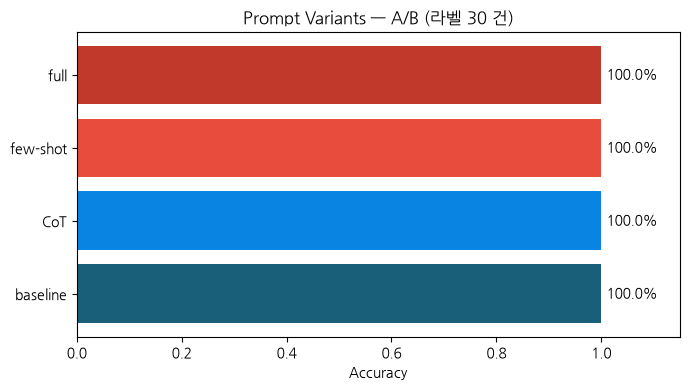

In [9]:
# === SOLUTION START ===
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(ab['변형'], ab['정확도'], color=['#1a5f7a', '#0984e3', '#e74c3c', '#c0392b'])
for i, v in enumerate(ab['정확도']):
    ax.text(v + 0.01, i, f'{v:.1%}', va='center')
ax.set_xlim(0, 1.15)
ax.set_xlabel('Accuracy')
ax.set_title('Prompt Variants — A/B (라벨 30 건)' + ('' if USE_REAL else ' · mock: 변형 구분 없음'))
plt.tight_layout(); plt.show()
# === SOLUTION END ===

---
## Step 4. 설명 품질 평가 — 본문 §10.4.1 의 네 조건

reasoning 의 **길이는 채점 기준이 아니다**(§10.4.1). 대신 네 조건을 각각 0/1 로 채점한다.

| 조건 | 자동 채점 방법 |
|---|---|
| 근거 기반(Grounded) | `fields_observed` 가 1 개 이상이고, 모든 value 가 실제 로그 값에 존재 (없는 필드를 지어내지 않았는가) |
| 검증 가능(Verifiable) | `reasoning` 이 로그의 실제 값을 하나 이상 그대로 인용 (분석가가 원본에서 찾아볼 수 있는가) |
| 반증 가능(Falsifiable) | `reasoning` 에 "~라면 판정이 달라진다" 류의 조건 표현이 있는가 |
| 대응 가능(Actionable) | `recommended_actions` 가 1 개 이상이고 공백이 아닌가 |

Step 3 의 `analyses` 를 그대로 채점하므로 추가 호출이 없다.

In [10]:
# === SOLUTION START ===
FALSIFY_PAT = re.compile(r'라면|다면|아니라면|뒤집|재판정|반증|만약|경우에는|if\s')

def log_values(log):
    return [str(v) for v in log.values() if str(v) not in ('', '-')]

def evaluate_explanation(log, a):
    vals = log_values(log)
    fo = a.get('fields_observed') or []
    grounded = bool(fo) and all(
        str(f.get('value', '')) and any(str(f.get('value')) in v or v in str(f.get('value'))
                                        for v in vals) for f in fo if isinstance(f, dict))
    reasoning = str(a.get('reasoning', ''))
    verifiable = any(v in reasoning for v in vals if len(v) > 2)
    falsifiable = bool(FALSIFY_PAT.search(reasoning))
    actions = [str(x).strip() for x in (a.get('recommended_actions') or [])]
    actionable = any(actions)
    return {'근거 기반': grounded, '검증 가능': verifiable,
            '반증 가능': falsifiable, '대응 가능': actionable}

xai_rows = []
per_item = {}
for name, outs in analyses.items():
    scores = [evaluate_explanation(log, a) for a, (log, _) in zip(outs, labeled)]
    per_item[name] = scores
    agg = {k: float(np.mean([s[k] for s in scores])) for k in scores[0]}
    xai_rows.append({'변형': name, **agg,
                     'XAI 점수(4점)': float(np.mean([sum(s.values()) for s in scores]))})
xai = pd.DataFrame(xai_rows)
print(xai.to_string(index=False, float_format=lambda v: f'{v:.2f}'))

print('\n--- 예시: 첫 변형의 로그 5 건 채점 ---')
first = list(PROMPTS)[0]
print(pd.DataFrame([{'url': log['url'][:40], 'truth': t, 'pred': a.get('category'), **s}
                    for (log, t), a, s in list(zip(labeled, analyses[first], per_item[first]))[:5]]
                   ).to_string(index=False))
# === SOLUTION END ===

      변형  근거 기반  검증 가능  반증 가능  대응 가능  XAI 점수(4점)
baseline   0.90   1.00   0.50   1.00        3.40
     CoT   0.93   1.00   0.60   1.00        3.53
few-shot   0.90   1.00   0.77   1.00        3.67
    full   0.90   1.00   0.83   1.00        3.73

--- 예시: 첫 변형의 로그 5 건 채점 ---
                      url  truth   pred  근거 기반  검증 가능  반증 가능  대응 가능
              /index.html BENIGN BENIGN   True   True  False   True
/products?category=laptop BENIGN BENIGN   True   True  False   True
           /static/app.js BENIGN BENIGN   True   True   True   True
                   /login BENIGN BENIGN   True   True  False   True
   /api/v1/users?limit=50 BENIGN BENIGN   True   True  False   True


In [11]:
# === SOLUTION START ===
# 최고 변형 선정 — 정확도 → XAI 점수 → 출력 토큰(비용) 순. 동점이면 무엇으로 갈랐는지 밝힌다.
summary = ab.merge(xai[['변형', 'XAI 점수(4점)']], on='변형')
ranked = summary.sort_values(['정확도', 'XAI 점수(4점)', '평균 출력 토큰'],
                             ascending=[False, False, True]).reset_index(drop=True)
print(ranked.to_string(index=False, formatters={'정확도': '{:.1%}'.format,
                                                '100 건 비용($)': '{:.4f}'.format,
                                                'XAI 점수(4점)': '{:.2f}'.format}))
top = ranked.iloc[0]
tied_acc = ranked[ranked['정확도'] == top['정확도']]['변형'].tolist()
tied_all = ranked[(ranked['정확도'] == top['정확도']) &
                  (ranked['XAI 점수(4점)'] == top['XAI 점수(4점)'])]['변형'].tolist()
print(f"\n최고 변형: {top['변형']}  (정확도 {top['정확도']:.1%} · XAI {top['XAI 점수(4점)']:.2f}/4 ·"
      f" 100 건 ${top['100 건 비용($)']:.4f})")
if len(tied_acc) > 1:
    print(f'정확도 동점: {tied_acc} -> XAI 점수로 구분')
if len(tied_all) > 1:
    print(f'정확도·XAI 모두 동점: {tied_all} -> 출력 토큰이 적은 쪽을 선택')
if not USE_REAL:
    print('mock 은 네 변형이 완전히 같으므로 이 선정은 의미가 없다 (동점 처리 경로만 확인된다).')
best_prompt = top['변형']
# === SOLUTION END ===

      변형    정확도  파싱 실패  출력 잘림  평균 입력 토큰  평균 출력 토큰 100 건 비용($) XAI 점수(4점)
    full 100.0%      0      0      1419       738      0.5108       3.73
few-shot 100.0%      0      0      1308       484      0.3726       3.67
     CoT 100.0%      0      0       640      1079      0.6033       3.53
baseline 100.0%      0      0       529       597      0.3512       3.40

최고 변형: full  (정확도 100.0% · XAI 3.73/4 · 100 건 $0.5108)
정확도 동점: ['full', 'few-shot', 'CoT', 'baseline'] -> XAI 점수로 구분


---
## 정리
- 네 변형은 본문 §10.2 의 스키마를 공유하고 CoT·few-shot 만 달리해, 차이가 그 두 요소에서만 오게 만들었습니다.
- 라벨 30 건은 서로 다른 로그이고 각 라벨의 근거가 로그 안에 있습니다. 경계 사례(난독화·인코딩·공격처럼 보이는 정상·느린 스캔) 가 변형 간 차이를 드러내는 자리입니다.
- 비교는 정확도 하나가 아니라 오답표·파싱 실패·출력 잘림·평균 출력 토큰(CoT 비용) 을 같이 봤습니다. CoT 계열은 출력 토큰이 늘어 비용이 올라갑니다.
- 정확도가 네 변형 모두 같게 나오면 "프롬프트는 상관없다" 가 아니라 "이 난이도에서 정확도가 포화됐다" 는 뜻입니다. 그때는 설명 품질과 비용이 선택 기준이 됩니다.
- 설명 품질은 §10.4.1 의 네 조건(근거·검증·반증·대응) 으로 0/1 채점했습니다. reasoning 길이는 쓰지 않았습니다.
- 최고 변형은 정확도 → XAI → 출력 토큰 순으로 고르고, 동점이면 무엇으로 갈랐는지 출력에 남겼습니다.
- mock 경로는 프롬프트를 읽지 않으므로 네 변형이 같은 결과를 냅니다. 변형 비교는 실제 호출에서만 유효합니다.

> **다음 챕터:** RAG 와 위협 인텔리전스 — CVE·MITRE·OWASP 데이터를 검색해 분석에 결합.